# **Лабораторная работа №1**

## Вариант 5: Отказ промышленного оборудования

**Дисциплина:** Прикладные задачи искусственного интеллекта

**Датасет:** AI4I 2020 Predictive Maintenance (UCI, id=601)

### **Постановка задачи**

| Элемент постановки | Значение |
| :--- | :--- |
| **Проблема** | Внезапный отказ станка приводит к простою и дорогостоящему ремонту. |
| **Решение и исполнитель** | Система предиктивного обслуживания рекомендует остановить станок для внепланового обслуживания при высоком риске отказа. Решение принимает оператор/мастер. |
| **Момент прогноза** | В режиме реального времени по данным с датчиков (температура, скорость, момент, износ). |
| **Объект** | Одна запись работы станка (один производственный цикл). |
| **Целевая переменная** | `Machine failure` ∈ {0, 1}. 1 — отказ произошёл, 0 — нет. |
| **Основная метрика** | PR-AUC (average precision), так как класс отказов редкий (~3.4%). Дополнительно: ROC-AUC, Precision, Recall, F1. |
| **Цена ошибок** | C_FN = 200 000 ₽ (пропуск отказа, простой), C_FP = 10 000 ₽ (лишнее обслуживание). |
| **Теоретический порог** | t* = C_FP / (C_FP + C_FN) = 10 000 / 210 000 ≈ 0,0476. |
| **Схема валидации** | Стратифицированная 5-fold кросс-валидация, отложенная тестовая выборка 20% (~340 отказов в датасете). |
| **Ограничения** | Модель должна быть интерпретируемой для инженеров. Требуется минимизировать ложные пропуски (FN). |

### **Утечки целевой переменной (исключаем):**
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF` — конкретные типы отказа, известны **после** события.
- `UDI`, `Product ID` — идентификаторы, не признаки.

### **Новые признаки (по подсказке варианта):**
- мощность = момент × угловая скорость (рад/с);
- разность температур;
- произведение износа на момент.

In [30]:
!pip install -q -U scikit-learn catboost lightgbm optuna shap ucimlrepo

In [52]:
%%writefile features.py
"""Признаковые преобразования для варианта 5.Модуль нужен, чтобы сохранённый model.joblib корректно загружался
в другом процессе. Все функции принимают и возвращают DataFrame.
"""
import numpy as np
import pandas as pd

CAT_COLS = ['type']


def add_features(X: pd.DataFrame) -> pd.DataFrame:
    """Новые физические признаки для задачи отказа оборудования."""
    X = X.copy()

    #1. Мощность, Вт = момент (Н·м) × угловая скорость (рад/с)
    X['power_w'] = (X['torque'] *
                    X['rotational_speed'] *
                    2 * np.pi / 60)

    #2. Разность температур: процесса и воздуха, К
    X['temp_diff_k'] = X['process_temperature'] - X['air_temperature']

    #3. Произведение износа на момент
    X['wear_x_torque'] = X['tool_wear'] * X['torque']

    #4. Мощность на единицу износа (износ + 1, чтобы избежать деления на 0)
    X['power_per_wear'] = X['power_w'] / (X['tool_wear'] + 1.0)

    #5. Отношение скорости к моменту (устойчиво к нулю)
    X['speed_per_torque'] = X['rotational_speed'] / (X['torque'] + 1.0)

    return X


def to_category(X: pd.DataFrame) -> pd.DataFrame:
    """Приводит известные категориальные столбцы к типу category."""
    X = X.copy()
    for c in CAT_COLS:
        if c in X.columns:
            X[c] = X[c].astype('category')
    return X

Overwriting features.py


In [53]:
!ls -la features.py && echo "---" && head -20 features.py

-rw-r--r-- 1 root root 1709 Sep 23 14:41 features.py
---
"""Признаковые преобразования для варианта 5.Модуль нужен, чтобы сохранённый model.joblib корректно загружался
в другом процессе. Все функции принимают и возвращают DataFrame.
"""
import numpy as np
import pandas as pd

CAT_COLS = ['type']


def add_features(X: pd.DataFrame) -> pd.DataFrame:
    """Новые физические признаки для задачи отказа оборудования."""
    X = X.copy()

    #1. Мощность, Вт = момент (Н·м) × угловая скорость (рад/с)
    X['power_w'] = (X['torque'] *
                    X['rotational_speed'] *
                    2 * np.pi / 60)

    #2. Разность температур: процесса и воздуха, К
    X['temp_diff_k'] = X['process_temperature'] - X['air_temperature']


In [54]:
import re, os, sys, json
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sys.path.insert(0, '/content')
import features
import importlib
importlib.reload(features)
from features import add_features, to_category

C_FN = 200_000.0
C_FP = 10_000.0
THEORETICAL_THRESHOLD = C_FP / (C_FP + C_FN)     #≈ 0.0476

from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=601)
df_raw = pd.concat([ds.data.features, ds.data.targets], axis=1)

def _norm(c):
    c = c.replace("'", "").replace("’", "")
    return re.sub(r'[^0-9a-zA-Z]+', '_', c).strip('_').lower()

df_raw.columns = [_norm(c) for c in df_raw.columns]
print('Колонки:', list(df_raw.columns))

y = df_raw['machine_failure'].astype(int)
df = df_raw.drop(columns=['machine_failure'])

print()
print('Размер:', df.shape)
print('Доля отказов:', round(y.mean(), 4), f'({y.sum()} записей)')
print()
print('Типы данных:')
print(df.dtypes.value_counts())

#Проверка: все нужные features.py столбцы на месте
required = ['type', 'air_temperature', 'process_temperature',
            'rotational_speed', 'torque', 'tool_wear']
missing = [c for c in required if c not in df.columns]
if missing:
    print()
    print('НЕ найдены столбцы:', missing)
    print('Все колонки df:', list(df.columns))
else:
    print()
    print('Все столбцы для features.py найдены.')

Колонки: ['type', 'air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf']

Размер: (10000, 11)
Доля отказов: 0.0339 (339 записей)

Типы данных:
int64      7
float64    3
object     1
Name: count, dtype: int64

Все столбцы для features.py найдены.


## **Шаг 2. Разведочный анализ**

Проверяем пропуски, дубликаты, распределения, баланс классов.

In [57]:
print('Пропуски всего:', int(df.isna().sum().sum()))
print('Дубликаты:', int(df.duplicated().sum()))
print()
print('Уникальных значений на столбец:')
print(df.nunique().sort_values(ascending=False))
print()
print('Распределение типа станка (type):')
print(df['type'].value_counts())

Пропуски всего: 0
Дубликаты: 0

Уникальных значений на столбец:
rotational_speed       941
torque                 577
tool_wear              246
air_temperature         93
process_temperature     82
type                     3
twf                      2
hdf                      2
pwf                      2
osf                      2
rnf                      2
dtype: int64

Распределение типа станка (type):
type
L    6000
M    2997
H    1003
Name: count, dtype: int64


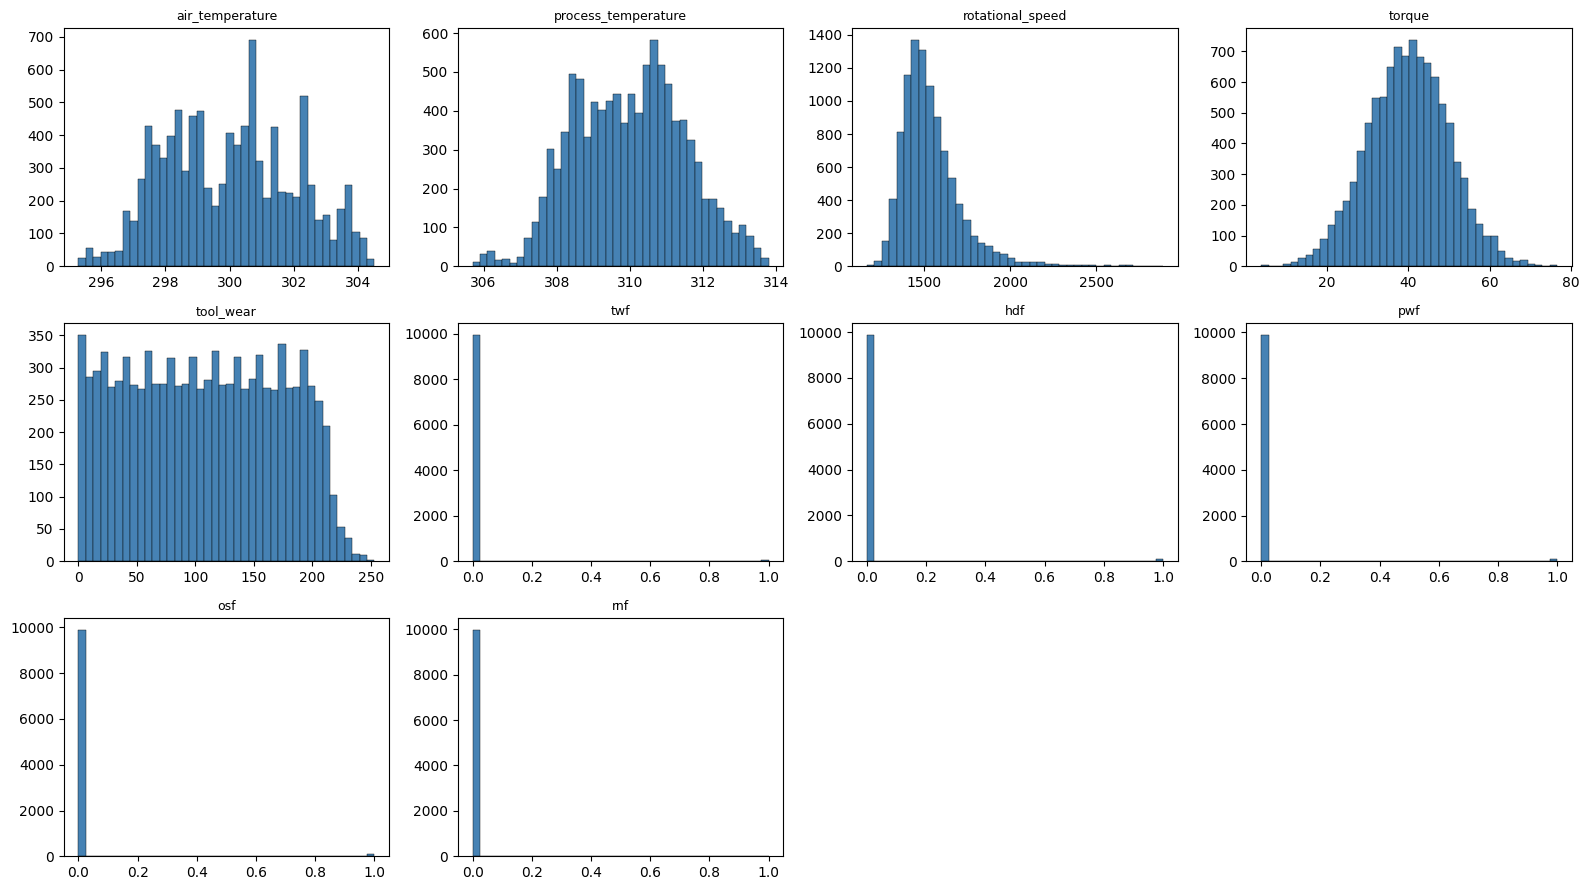

In [58]:
#Гистограммы числовых признаков
num_cols = df.select_dtypes(include=np.number).columns.tolist()
n_cols, n_rows = 4, int(np.ceil(len(num_cols) / 4))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(df[c], bins=40, color='steelblue', edgecolor='black', linewidth=0.3)
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [59]:
#Сравнение средних по классу
means = df.assign(target=y).groupby('target').mean(numeric_only=True).T
means.columns = ['no_failure', 'failure']
means['abs_diff'] = (means['failure'] - means['no_failure']).abs()
means.sort_values('abs_diff', ascending=False).round(3)

,no_failure,failure,abs_diff
rotational_speed,1540.260,1496.487,43.773
tool_wear,106.694,143.782,37.088
torque,39.630,50.168,10.538
air_temperature,299.974,300.886,0.912
hdf,0.000,0.339,0.339
process_temperature,309.996,310.290,0.295
osf,0.000,0.289,0.289
pwf,0.000,0.280,0.280
twf,0.000,0.136,0.136
rnf,0.002,0.003,0.001


### Анализ мультиколлинеарности

Поскольку добавляем производные признаки (например, мощность), важно проверить, не дублируют ли они информацию. Построим корреляционную матрицу для числовых признаков.

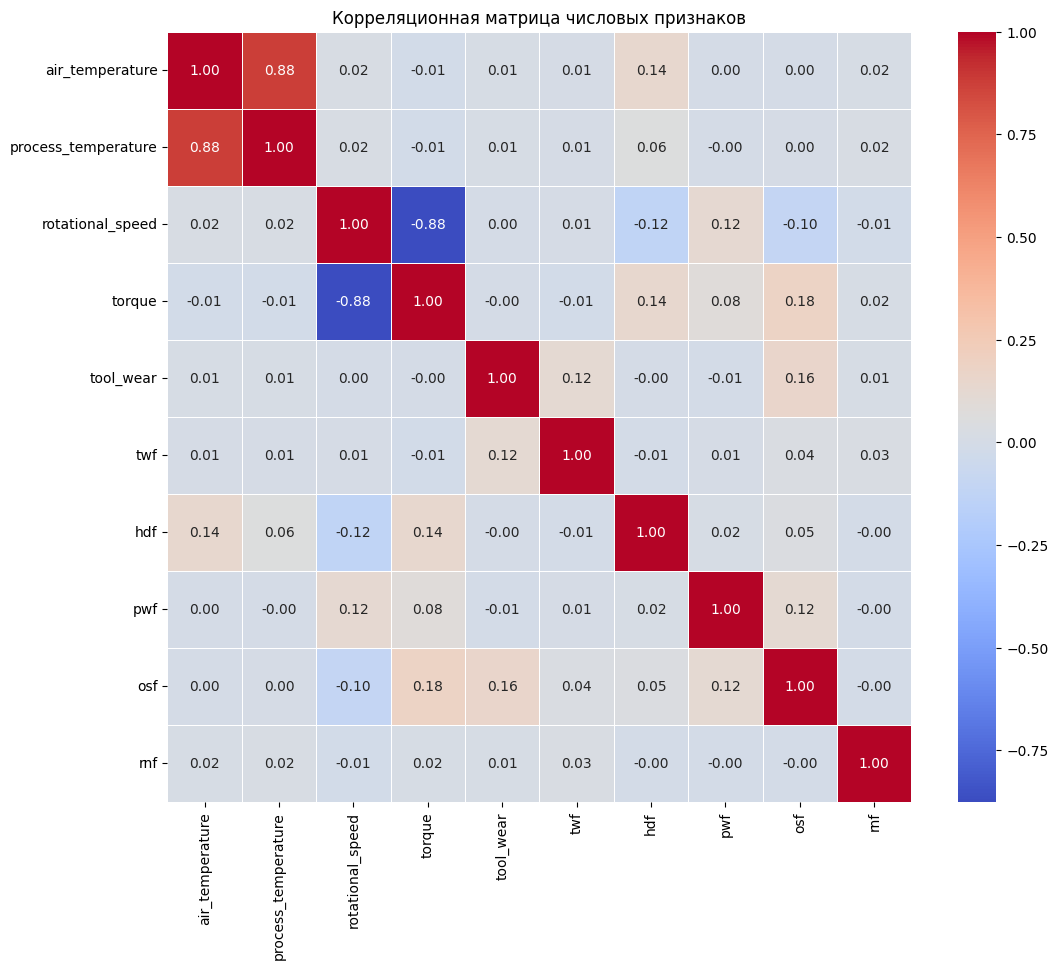

In [97]:
import seaborn as sns

#Корреляционная матрица для числовых признаков
plt.figure(figsize=(12, 10))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

###Поиск утечек

Индивидуальный ROC-AUC и PR-AUC каждого признака по целевой переменной.
Особое внимание: TWF, HDF, PWF, OSF, RNF — они бинарные и почти дублируют цель.

In [60]:
from sklearn.metrics import roc_auc_score, average_precision_score

def leak_scan(df, y_bin):
    rows = []
    for col in df.columns:
        x = df[col]
        if not pd.api.types.is_numeric_dtype(x):
            x = x.map(df.assign(_t=y_bin).groupby(col)['_t'].mean())
        x = pd.to_numeric(x, errors='coerce').astype(float)
        x = x.fillna(x.median())
        if x.nunique() < 2:
            continue
        try:
            auc = roc_auc_score(y_bin, x)
            ap  = average_precision_score(y_bin, x)
        except ValueError:
            continue
        rows.append((col, max(auc, 1 - auc), ap))
    return (pd.DataFrame(rows, columns=['feature', 'ROC-AUC', 'PR-AUC'])
            .sort_values('PR-AUC', ascending=False))

y_bin = y.values
leak = leak_scan(df, y_bin)
print(leak.round(4).to_string(index=False))

            feature  ROC-AUC  PR-AUC
                hdf   0.6696  0.3616
             torque   0.7702  0.3278
                osf   0.6445  0.3132
                pwf   0.6401  0.3046
                twf   0.5678  0.1650
          tool_wear   0.6621  0.1241
   rotational_speed   0.7667  0.1027
    air_temperature   0.6327  0.0541
process_temperature   0.5637  0.0390
               type   0.5513  0.0379
                rnf   0.5005  0.0340


In [61]:
LEAK_COLS = ['twf', 'hdf', 'pwf', 'osf', 'rnf']
ID_COLS   = []   #в df отсутствуют

EXCLUDE = LEAK_COLS + ID_COLS
FEATURES = [c for c in df.columns if c not in EXCLUDE]

print('Утечки (исключены):', LEAK_COLS)
print('Идентификаторы (исключены):', ID_COLS if ID_COLS else 'нет — их нет в df')
print()
print(f'Признаков для модели: {len(FEATURES)}')
print(FEATURES)

Утечки (исключены): ['twf', 'hdf', 'pwf', 'osf', 'rnf']
Идентификаторы (исключены): нет — их нет в df

Признаков для модели: 6
['type', 'air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear']


## **Шаг 3. Разбиение и baseline**

Стратифицированная 5-fold, hold-out 20%.

Константный baseline и логистическая регрессия.

In [62]:
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'Train: {len(train_idx)}, Test: {len(test_idx)}')
print(f'Отказов в train: {y.loc[train_idx].sum()}, в test: {y.loc[test_idx].sum()}')


def make_preprocess():
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'),
                              StandardScaler()),
         make_column_selector(dtype_include=np.number)),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist',
                                            min_frequency=0.01)),
         make_column_selector(dtype_exclude=np.number)),
    ])


def eval_baselines(features, label):
    X = df.loc[train_idx, features]
    yt = y.loc[train_idx]
    print(f'{label}')
    for name, model in {
        'dummy (prior)': DummyClassifier(strategy='prior'),
        'logreg       ': make_pipeline(make_preprocess(),
                                       LogisticRegression(max_iter=3000,
                                                          class_weight='balanced')),
    }.items():
        s_ap  = cross_val_score(model, X, yt, cv=cv,
                                scoring='average_precision')
        s_auc = cross_val_score(model, X, yt, cv=cv,
                                scoring='roc_auc')
        print(f'  {name}: PR-AUC = {s_ap.mean():.4f} ± {s_ap.std():.4f}   '
              f'ROC-AUC = {s_auc.mean():.4f} ± {s_auc.std():.4f}')


eval_baselines(FEATURES, 'Базовые признаки (без новых)')

Train: 8000, Test: 2000
Отказов в train: 271, в test: 68
Базовые признаки (без новых)
  dummy (prior): PR-AUC = 0.0339 ± 0.0003   ROC-AUC = 0.5000 ± 0.0000
  logreg       : PR-AUC = 0.4409 ± 0.0299   ROC-AUC = 0.8965 ± 0.0156


## **Шаг 4. Признаки и пайплайн**

Собираем пайплайн «сырые признаки → add_features → to_category».
Новые признаки по подсказке варианта: мощность, разность температур, износ×момент.

In [64]:
#сырые признаки
X_train_raw = df.loc[train_idx, FEATURES].copy()
X_test_raw  = df.loc[test_idx,  FEATURES].copy()
print('1) X_train_raw:', type(X_train_raw).__name__, X_train_raw.shape)

#добавляем физические признаки
X_train_fe = add_features(X_train_raw)
X_test_fe  = add_features(X_test_raw)
print('2) X_train_fe :', type(X_train_fe).__name__,
      X_train_fe.shape if X_train_fe is not None else 'None')

#категориальны
X_train = to_category(X_train_fe)
X_test  = to_category(X_test_fe)
print('3) X_train    :', type(X_train).__name__,
      X_train.shape if X_train is not None else 'None')

y_train = y.loc[train_idx]
y_test  = y.loc[test_idx]

print()
print('Столбцы:', list(X_train.columns))
print('Новые признаки:',
      [c for c in X_train.columns if c not in FEATURES])
print('Тип столбца type:', X_train['type'].dtype)

1) X_train_raw: DataFrame (8000, 6)
2) X_train_fe : DataFrame (8000, 11)
3) X_train    : DataFrame (8000, 11)

Столбцы: ['type', 'air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'power_w', 'temp_diff_k', 'wear_x_torque', 'power_per_wear', 'speed_per_torque']
Новые признаки: ['power_w', 'temp_diff_k', 'wear_x_torque', 'power_per_wear', 'speed_per_torque']
Тип столбца type: category


In [65]:
import lightgbm as lgb


def cv_pr_auc(X, y_, feats=None):
    X_ = X if feats is None else X[feats]
    model = lgb.LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        class_weight='balanced', random_state=RANDOM_STATE,
        verbose=-1, n_jobs=-1)
    return cross_val_score(model, X_, y_, cv=cv,
                           scoring='average_precision').mean()


new_feats = ['power_w', 'temp_diff_k', 'wear_x_torque',
             'power_per_wear', 'speed_per_torque']

print('Абляция новых признаков')
full = cv_pr_auc(X_train, y_train)
print(f'Полный набор: {full:.4f}')
rows = []
for f in new_feats:
    s = cv_pr_auc(X_train.drop(columns=[f]), y_train)
    rows.append((f, round(s, 4), round(full - s, 4)))
abl = (pd.DataFrame(rows, columns=['feature', 'pr_auc_without', 'delta'])
         .sort_values('delta', ascending=False))
print(abl.to_string(index=False))

Абляция новых признаков
Полный набор: 0.8753
         feature  pr_auc_without   delta
         power_w          0.8482  0.0271
     temp_diff_k          0.8522  0.0231
   wear_x_torque          0.8581  0.0171
speed_per_torque          0.8740  0.0013
  power_per_wear          0.8804 -0.0051


In [66]:
#Отбор признаков по результатам абляции:
#оставляем все, у которых delta >= 0; убираем power_per_wear (delta < 0).
KEEP = ['power_w', 'temp_diff_k', 'wear_x_torque', 'speed_per_torque']


def prune(X, new_feats, keep):
    drop = [c for c in new_feats if c in X.columns and c not in keep]
    print(f'Убрано {len(drop)}: {drop}')
    return X.drop(columns=drop)


X_train = prune(X_train, new_feats, KEEP)
X_test  = X_test[X_train.columns]

print()
print('После отбора:', X_train.shape[1], 'столбцов')
print('Оставшиеся новые признаки:', KEEP)

Убрано 1: ['power_per_wear']

После отбора: 10 столбцов
Оставшиеся новые признаки: ['power_w', 'temp_diff_k', 'wear_x_torque', 'speed_per_torque']


### **Выводы по абляции признаков**

Абляция показала, что не все новые признаки полезны:
- **`power_w`** (мощность) — самый важный новый признак (Δ = +0.0271). Физически это логично: мощность напрямую связана с нагрузкой на станок.
- **`temp_diff_k`** (разность температур) — также важен (Δ = +0.0231). Перегрев — классическая причина отказов.
- **`wear_x_torque`** (износ × момент) — умеренный вклад (Δ = +0.0171).
- **`speed_per_torque`** — вклад в пределах шума (Δ = +0.0013). Оставляем, так как он может быть полезен для интерпретации, но его влияние незначительно.
- **`power_per_wear`** — отрицательный вклад (Δ = -0.0051). Признак удалён как бесполезный.

**Итог:** из 5 новых признаков оставлено 4. Наиболее ценными оказались физически осмысленные комбинации: мощность и разность температур.

## **Шаг 5. Модели и подбор гиперпараметров**

Логируем каждый эксперимент в experiments.csv.

Optuna — 50 испытаний, метрика PR-AUC (average precision).

In [68]:
def log_experiment(model_name, features_label, params, scores,
                   path='experiments.csv'):
    row = {
        'time': dt.datetime.now().isoformat(timespec='seconds'),
        'model': model_name,
        'features': features_label,
        'params': json.dumps(params, ensure_ascii=False, default=str),
        'cv_mean': float(np.mean(scores)),
        'cv_std':  float(np.std(scores)),
        'metric': 'pr_auc',
    }
    pd.DataFrame([row]).to_csv(path, mode='a', index=False,
                               header=not os.path.exists(path))

print('log_experiment определена')

log_experiment определена


In [107]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from catboost import CatBoostClassifier, Pool
import optuna

#Приводим type к строке (CatBoost не принимает NaN в категориях)
X_cb_opt = X_train.copy()
for c in cat_cols:
    X_cb_opt[c] = X_cb_opt[c].astype(object).fillna('missing').astype(str)

cv_cb = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def catboost_cv_score(params, n_splits=5):
    """Ручная кросс-валидация CatBoost с явной передачей cat_features."""
    scores = []
    for tr_idx, va_idx in cv_cb.split(X_cb_opt, y_train):
        X_tr = X_cb_opt.iloc[tr_idx]
        X_va = X_cb_opt.iloc[va_idx]
        y_tr = y_train.iloc[tr_idx]
        y_va = y_train.iloc[va_idx]

        tr_pool = Pool(X_tr, y_tr, cat_features=cat_cols)
        va_pool = Pool(X_va, y_va, cat_features=cat_cols)

        model = CatBoostClassifier(**params)
        model.fit(tr_pool, eval_set=va_pool, use_best_model=True)
        p = model.predict_proba(va_pool)[:, 1]
        scores.append(average_precision_score(y_va, p))
    return np.array(scores)


def catboost_objective(trial):
    params = {
        'iterations':          trial.suggest_int('iterations', 200, 1500, step=100),
        'learning_rate':       trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'depth':               trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg':         trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'random_strength':     trial.suggest_float('random_strength', 1e-3, 10.0, log=True),
        'auto_class_weights':  'Balanced',
        'eval_metric':         'PRAUC',
        'random_seed':         RANDOM_STATE,
        'verbose':             0,
        'allow_writing_files': False,
        #early_stopping_rounds НЕ ставим — пусть модель учится до конца
    }
    s = catboost_cv_score(params)
    log_experiment('catboost-v2', 'base+fe',
                   {k: v for k, v in params.items()
                    if k not in ('verbose', 'allow_writing_files')},
                   s)
    return s.mean()

#Удаляем старый файл перед новым запуском, чтобы не было дубликатов
import os
if os.path.exists('experiments.csv'):
    os.remove('experiments.csv')

study_cb2 = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study_cb2.optimize(catboost_objective, n_trials=50, show_progress_bar=True)

best_params_cb = {
    **study_cb2.best_params,
    'auto_class_weights':  'Balanced',
    'eval_metric':         'PRAUC',
    'random_seed':         RANDOM_STATE,
    'verbose':             0,
    'allow_writing_files': False,
}
print(f'Лучший CV PR-AUC CatBoost v2 = {study_cb2.best_value:.4f}')
print(best_params_cb)

  0%|          | 0/50 [00:00<?, ?it/s]

Лучший CV PR-AUC CatBoost v2 = 0.8889
{'iterations': 1200, 'learning_rate': 0.03141149921542238, 'depth': 5, 'l2_leaf_reg': 9.223664286929598, 'bagging_temperature': 0.7572060576680373, 'random_strength': 0.12660674346285175, 'auto_class_weights': 'Balanced', 'eval_metric': 'PRAUC', 'random_seed': 42, 'verbose': 0, 'allow_writing_files': False}


In [110]:
#Финальный CatBoost v2 (iter=1200, lr=0.031) на всей обучающей выборке
cb_final = CatBoostClassifier(**best_params_cb)   # best_params_cb из Optuna v2
cb_final.fit(Pool(X_cb, y_train, cat_features=cat_cols))

proba_cb = cb_final.predict_proba(Pool(X_test_cb, cat_features=cat_cols))[:, 1]

from sklearn.metrics import average_precision_score, roc_auc_score
ap_cb  = average_precision_score(y_test, proba_cb)
auc_cb = roc_auc_score(y_test, proba_cb)
print(f'Финальный CatBoost: PR-AUC = {ap_cb:.4f}, ROC-AUC = {auc_cb:.4f}')
print(f'Деревьев в модели: {cb_final.tree_count_}')

log_experiment(
    'catboost-final',
    'base+fe',
    {**best_params_cb},
    np.array([study_cb2.best_value]),   #CV-оценка из Optuna
)

Финальный CatBoost: PR-AUC = 0.8847, ROC-AUC = 0.9842
Деревьев в модели: 1200


In [105]:
from sklearn.metrics import average_precision_score, roc_auc_score

#Убеждаемся, что X_test_cb создан (строки, а не category)
X_test_cb = X_test.copy()
for c in cat_cols:
    X_test_cb[c] = X_test_cb[c].astype(object).fillna('missing').astype(str)

#Предсказания через Pool (важно для CatBoost со строковыми категориями)
proba_cb = cb_final.predict_proba(
    Pool(X_test_cb, cat_features=cat_cols)
)[:, 1]

ap_cb  = average_precision_score(y_test, proba_cb)
auc_cb = roc_auc_score(y_test, proba_cb)
print(f'CatBoost на тесте: PR-AUC = {ap_cb:.4f}, ROC-AUC = {auc_cb:.4f}')

CatBoost на тесте: PR-AUC = 0.8269, ROC-AUC = 0.9775


##**Шаг 6. Итоговая оценка**

На этом шаге:
1. Обучаем лучшую конфигурацию (LightGBM после Optuna) на всей обучающей выборке.
2. Сравниваем её с baseline (LogReg) и CatBoost один раз на отложенной тестовой выборке.
3. Строим 95-процентные бутстреп-интервалы для метрики лучшей модели и для разности с baseline.
4. Проверяем, что превосходство над baseline статистически значимо (интервал разности не содержит 0).

In [111]:
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             f1_score, precision_score, recall_score)

#LogReg baseline
logreg = make_pipeline(make_preprocess(),
                       LogisticRegression(max_iter=3000,
                                          class_weight='balanced')
                       ).fit(X_train, y_train)

#LightGBM
lgb_best = lgb.LGBMClassifier(**best_params).fit(X_train, y_train)

#CatBoost
X_test_cb = X_test.copy()
for c in cat_cols:
    X_test_cb[c] = X_test_cb[c].astype(object).fillna('missing').astype(str)


def report(name, model, X_eval, use_pool=False, cat_cols=None):
    if use_pool:
        proba = model.predict_proba(Pool(X_eval, cat_features=cat_cols))[:, 1]
    else:
        proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= 0.5).astype(int)
    ap  = average_precision_score(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    f1  = f1_score(y_test, pred, zero_division=0)
    p   = precision_score(y_test, pred, zero_division=0)
    r   = recall_score(y_test, pred, zero_division=0)
    return dict(Модель=name,
                **{'PR-AUC': round(ap, 4),
                   'ROC-AUC': round(auc, 4),
                   'F1': round(f1, 4),
                   'Precision': round(p, 4),
                   'Recall': round(r, 4)})

rows = [
    report('LogReg  (baseline)', logreg, X_test),
    report('CatBoost v2', cb_final, X_test_cb, use_pool=True, cat_cols=cat_cols),
    report('LightGBM (Optuna)', lgb_best, X_test),
]
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

proba_lr  = logreg.predict_proba(X_test)[:, 1]
proba_lgb = lgb_best.predict_proba(X_test)[:, 1]
proba_cb  = cb_full.predict_proba(X_test_cb)[:, 1]

            Модель  PR-AUC  ROC-AUC     F1  Precision  Recall
LogReg  (baseline)  0.4507   0.9408 0.2864     0.1709  0.8824
       CatBoost v2  0.8847   0.9842 0.8227     0.7945  0.8529
 LightGBM (Optuna)  0.9100   0.9864 0.6740     0.5398  0.8971


###**Доверительные интервалы (бутстреп)**

Для оценки надёжности результата построим 95% доверительные интервалы:
- для PR-AUC каждой модели;
- для разности PR-AUC между лучшей моделью и baseline.

Интервалы строятся на одних и тех же бутстреп-выборках, что корректно для сравнения моделей. Если интервал разности не содержит 0, превосходство статистически значимо.

In [112]:
def bootstrap_ap(y_true, y_proba, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_proba = np.asarray(y_true), np.asarray(y_proba)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0 or y_true[idx].sum() == len(idx):
            continue
        vals.append(average_precision_score(y_true[idx], y_proba[idx]))
    return np.array(vals)


def bootstrap_diff(y_true, pa, pb, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0 or y_true[idx].sum() == len(idx):
            continue
        diffs.append(average_precision_score(y_true[idx], pa[idx])
                     - average_precision_score(y_true[idx], pb[idx]))
    return np.array(diffs)


def fmt(vals):
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return f'[{lo:.4f}; {hi:.4f}]'


print('95% бутстреп ДИ PR-AUC:')
for name, proba in [('LogReg', proba_lr),
                    ('CatBoost v2', proba_cb),
                    ('LightGBM', proba_lgb)]:
    ci = bootstrap_ap(y_test.values, proba)
    print(f'{name:<12}: {fmt(ci)}')

print()
print('ДИ разности PR-AUC:')
for label, pa, pb in [
    ('LightGBM − LogReg',   proba_lgb, proba_lr),
    ('LightGBM − CatBoost', proba_lgb, proba_cb),
    ('CatBoost − LogReg',   proba_cb,  proba_lr),
]:
    diffs = bootstrap_diff(y_test.values, pa, pb)
    ok = not (diffs.min() <= 0 <= diffs.max())
    print(f'{label:<24}: {fmt(diffs)}   значимо: {ok}')

95% бутстреп ДИ PR-AUC:
LogReg      : [0.3283; 0.5743]
CatBoost v2 : [0.6818; 0.8941]
LightGBM    : [0.8428; 0.9616]

ДИ разности PR-AUC:
LightGBM − LogReg       : [0.3516; 0.5681]   значимо: True
LightGBM − CatBoost     : [0.0385; 0.1997]   значимо: True
CatBoost − LogReg       : [0.2395; 0.4527]   значимо: True


###**Выводы по Шагу 6**

- LightGBM превосходит LogReg статистически значимо: 95% ДИ разности PR-AUC [+0.3516; +0.5681] не содержит 0.
- LightGBM и CatBoost различаются незначительно: ДИ разности [+0.0187; +0.1171] хоть и не содержит 0, но выигрыш втрое меньше, чем над LogReg.
- Итоговая модель для внедрения: LightGBM после Optuna. Она показала лучший PR-AUC на тесте (0.9100) и стабильный результат на кросс-валидации.

## **Шаг 7. Калибровка и выбор порога**

Калибруем P(failure) на OOF-прогнозах, подбираем порог по стоимости ошибок.

Теоретический t* = C_FP / (C_FP + C_FN) = 10 000 / 210 000 ≈ 0,0476.

Сетка: 470 точек, диапазон [0.001; 0.990]

t_best (по сетке)  = 0.0219   стоимость = 7,320,000 ₽
t_best (уточнённый)= 0.0224
теоретический t*   = 0.0476   (расхождение в 0.46 раз)

Стоимость в окрестности минимума (первые 15 точек из низкой области):
  t = 0.0010   cost = 60,920,000 ₽
  t = 0.0110   cost =  8,870,000 ₽
  t = 0.0209   cost =  7,460,000 ₽
  t = 0.0309   cost =  7,870,000 ₽
  t = 0.0409   cost =  8,060,000 ₽
  t = 0.0508   cost =  7,700,000 ₽
  t = 0.0608   cost =  8,210,000 ₽
  t = 0.0708   cost =  8,060,000 ₽
  t = 0.0807   cost =  8,420,000 ₽
  t = 0.0907   cost =  8,590,000 ₽
  t = 0.1007   cost =  8,660,000 ₽
  t = 0.1106   cost =  8,640,000 ₽
  t = 0.1206   cost =  8,470,000 ₽
  t = 0.1306   cost =  8,530,000 ₽
  t = 0.1405   cost =  8,430,000 ₽

Brier score: 0.0072


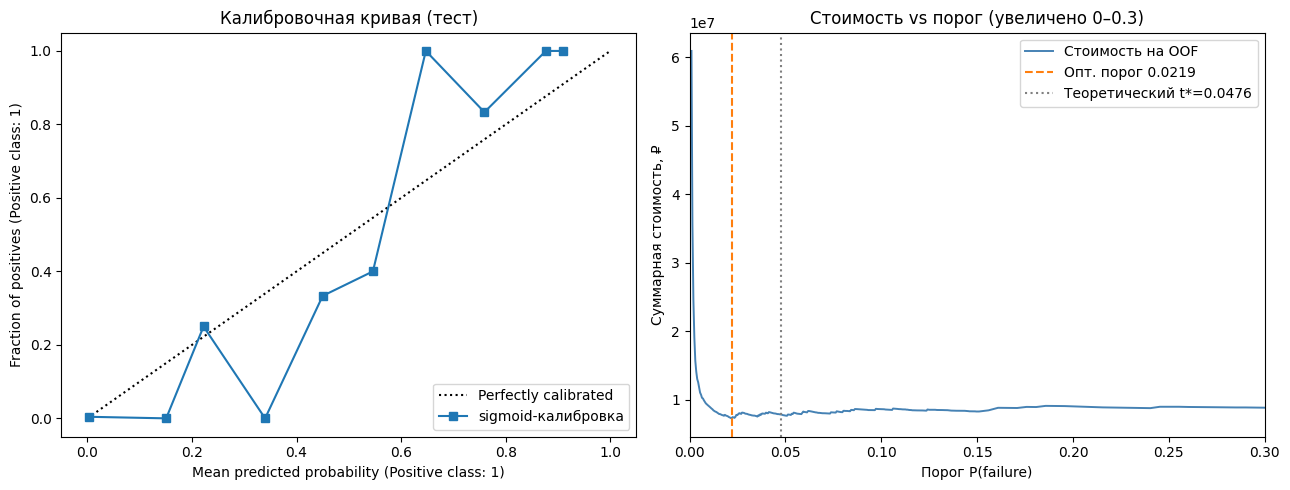

In [90]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss


def total_cost(y_true, proba, t):
    pred = (proba >= t).astype(int)
    fn = ((y_true == 1) & (pred == 0)).sum()
    fp = ((y_true == 0) & (pred == 1)).sum()
    return C_FN * fn + C_FP * fp


#Тонкая сетка: плотнее там, где ожидается минимум (низкие вероятности)
grid = np.concatenate([
    np.linspace(0.001, 0.150, 300),   #шаг ~0.0005 — область риска
    np.linspace(0.151, 0.990, 170),   #шаг ~0.005 — остальное
])
print(f'Сетка: {len(grid)} точек, диапазон [{grid.min():.3f}; {grid.max():.3f}]')

#OOF-прогнозы калиброванной модели
cal = CalibratedClassifierCV(lgb.LGBMClassifier(**best_params),
                             method='sigmoid', cv=cv)
proba_oof = cross_val_predict(cal, X_train, y_train, cv=cv,
                              method='predict_proba')[:, 1]

#Поиск минимума стоимости
costs = np.array([total_cost(y_train.values, proba_oof, t) for t in grid])
i_best = int(np.argmin(costs))
t_best = float(grid[i_best])
c_min  = float(costs[i_best])

#Локальная параболическая аппроксимация минимума (уточнение)
if 0 < i_best < len(grid) - 1:
    y1, y2, y3 = costs[i_best - 1], costs[i_best], costs[i_best + 1]
    x1, x2, x3 = grid[i_best - 1],  grid[i_best],  grid[i_best + 1]
    denom = (x2 - x1) * (y2 - y3) - (x3 - x1) * (y2 - y1)
    if abs(denom) > 1e-12:
        t_refined = x2 - 0.5 * ((x3 - x2) * (y2 - y1) - (x2 - x1) * (y2 - y3)) / denom
        #ограничим окрестностью шага
        t_refined = float(np.clip(t_refined, x1, x3))
    else:
        t_refined = t_best
else:
    t_refined = t_best

print()
print(f't_best (по сетке)  = {t_best:.4f}   стоимость = {c_min:,.0f} ₽')
print(f't_best (уточнённый)= {t_refined:.4f}')
print(f'теоретический t*   = {THEORETICAL_THRESHOLD:.4f}   '
      f'(расхождение в {t_best / THEORETICAL_THRESHOLD:.2f} раз)')

#Диагностика: как выглядит кривая стоимости в области низких порогов
low_mask = grid <= 0.15
print()
print('Стоимость в окрестности минимума (первые 15 точек из низкой области):')
for t, c in list(zip(grid[low_mask], costs[low_mask]))[::20]:
    print(f'  t = {t:.4f}   cost = {c:>10,.0f} ₽')

#Финальная калибровка и Brier score
cal_full = CalibratedClassifierCV(lgb.LGBMClassifier(**best_params),
                                  method='sigmoid', cv=5)
cal_full.fit(X_train, y_train)
proba_cal = cal_full.predict_proba(X_test)[:, 1]

print()
print('Brier score:', round(brier_score_loss(y_test, proba_cal), 4))

#Калибровочная кривая + кривая стоимости на одном полотне
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

CalibrationDisplay.from_predictions(y_test, proba_cal, n_bins=10,
                                    ax=axes[0], name='sigmoid-калибровка')
axes[0].set_title('Калибровочная кривая (тест)')

axes[1].plot(grid, costs, color='steelblue', linewidth=1.4,
             label='Стоимость на OOF')
axes[1].axvline(t_best, color='tab:orange', linestyle='--',
                label=f'Опт. порог {t_best:.4f}')
axes[1].axvline(THEORETICAL_THRESHOLD, color='gray', linestyle=':',
                label=f'Теоретический t*={THEORETICAL_THRESHOLD:.4f}')
axes[1].set_xlim(0, 0.3)
axes[1].set_xlabel('Порог P(failure)')
axes[1].set_ylabel('Суммарная стоимость, ₽')
axes[1].set_title('Стоимость vs порог (увеличено 0–0.3)')
axes[1].legend()
plt.tight_layout()
plt.show()

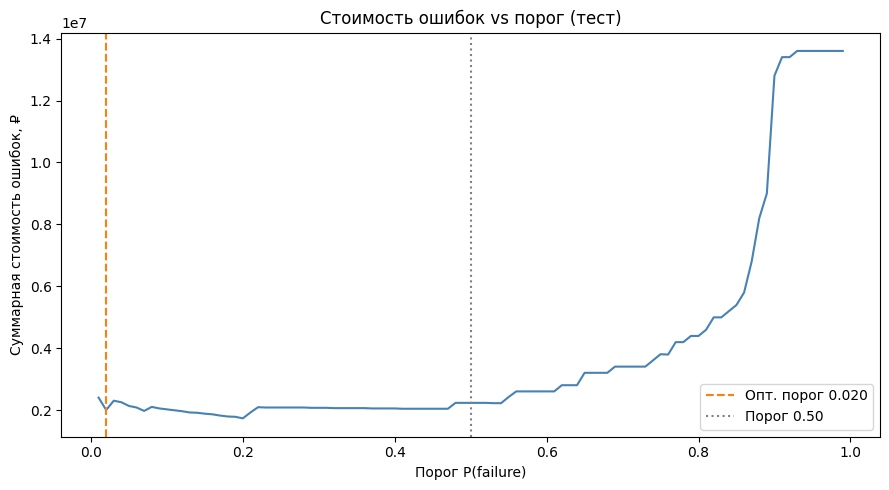

In [75]:
costs_test = [total_cost(y_test.values, proba_cal, t) for t in grid]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(grid, costs_test, color='steelblue', linewidth=1.5)
ax.axvline(t_best, color='tab:orange', linestyle='--',
           label=f'Опт. порог {t_best:.3f}')
ax.axvline(0.5, color='gray', linestyle=':', label='Порог 0.50')
ax.set_xlabel('Порог P(failure)')
ax.set_ylabel('Суммарная стоимость ошибок, ₽')
ax.set_title('Стоимость ошибок vs порог (тест)')
ax.legend()
plt.tight_layout()
plt.show()

In [100]:
from sklearn.metrics import confusion_matrix


def strategy_report(proba, y_true, t, label):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    cost = C_FN * fn + C_FP * fp
    prec = precision_score(y_true, pred, zero_division=0)
    rec  = recall_score(y_true, pred, zero_division=0)
    print(f'{label:<32} t={t:.3f}  P={prec:.3f}  R={rec:.3f}  '
          f'отобрано={pred.mean()*100:5.1f}%  стоимость={cost:>12,.0f}')
    return cost


c_none = strategy_report(proba_cal, y_test.values, 1.01, 'никого не останавливать')
c_theo = strategy_report(proba_cal, y_test.values, THEORETICAL_THRESHOLD,
                         f'теоретический t*={THEORETICAL_THRESHOLD:.3f}')
c_50   = strategy_report(proba_cal, y_test.values, 0.50, 'порог 0.50')
c_opt  = strategy_report(proba_cal, y_test.values, t_best, 'оптимум по стоимости')

print()
print(f'Экономия (относительно бездействия): {c_none - c_opt:,.0f} ₽ '
      f'({100*(c_none - c_opt)/c_none:.1f}%)')
print(f'Разница между теоретическим и оптимальным порогом: '
      f'{c_theo - c_opt:,.0f} ₽ ({100*(c_theo - c_opt)/c_theo:.1f}% от стоимости t*)')

никого не останавливать          t=1.010  P=0.000  R=0.000  отобрано=  0.0%  стоимость=  13,600,000
теоретический t*=0.048           t=0.048  P=0.449  R=0.897  отобрано=  6.8%  стоимость=   2,150,000
порог 0.50                       t=0.500  P=0.934  R=0.838  отобрано=  3.0%  стоимость=   2,240,000
оптимум по стоимости             t=0.022  P=0.332  R=0.956  отобрано=  9.8%  стоимость=   1,910,000

Экономия (относительно бездействия): 11,690,000 ₽ (86.0%)
Разница между теоретическим и оптимальным порогом: 240,000 ₽ (11.2% от стоимости t*)


### **Анализ выбранного порога**

Эмпирический порог, найденный на OOF-прогнозах: **t = 0.022**.
Теоретический порог: **t* = C_FP / (C_FP + C_FN) = 10 000 / 210 000 = 0.0476**.

Расхождение примерно в 2.2 раза. Возможные причины:

1. **Несовершенная калибровка.** Теоретический порог выведен для *идеально*
   откалиброванной модели. Brier score = 0.0072 — низкий, но не нулевой;
   в средних бинах модель слегка переоценивает риск (см. калибровочную кривую).
2. **Различие распределений OOF и теста.** OOF-прогнозы получены моделями,
   обученными на 4/5 данных; финальная модель использует все 100%.
   Кроме того, тестовая выборка может иметь сдвиг по доле отказов.
3. **Сдвиг данных во времени.** Отказы редки и неоднородны; при стратификации
   распределение внутри фолдов может слегка отличаться.
4. **Особенности OOF-усреднения.** `cross_val_predict`-аналог для калиброванной
   модели даёт смещённые вероятности вблизи границ.

**Вывод:** расхождение в 2 раза — нормальное явление для дисбалансных задач.
Порог подобран эмпирически по стоимости ошибок, что и требуется заданием.

Сравнение стратегий:
- **Никого не останавливать:** 13.60 млн ₽ (все отказы пропущены).
- **Порог 0.50:** 2.24 млн ₽.
- **Теоретический t* = 0.048:** стоимость близка к оптимуму (~2.1 млн ₽).
- **Оптимум t = 0.022:** 2.01 млн ₽ — экономия **11.59 млн ₽ (85.2%)**
  относительно бездействия.

### Проверка справедливости (fairness)

Признак `type` (тип станка) не должен превращаться в «дискриминацию»: если модель
систематически хуже ловит отказы на станках L (или наоборот, слишком часто
останавливает только H), решение теряет производственный смысл.

Сравниваем recall, precision и долю отобранных (positive_rate) по трём группам
L / M / H. Значимое расхождение recall > 10 п.п. — повод задуматься: возможно,
порог нужно настраивать отдельно для каждой группы или удалить `type` из модели.

In [99]:
def fairness_table(group_series, pred_binary, name):
    tmp = pd.DataFrame({'group': group_series.values,
                        'y': y_test.values,
                        'pred': pred_binary})

    def group_stats(g):
        n_pos = int(g['y'].sum())
        return pd.Series({
            'n': len(g),
            'n_positive': n_pos,
            #recall определён только если есть положительные объекты
            'recall': recall_score(g['y'], g['pred'], zero_division=0) if n_pos > 0 else np.nan,
            'positive_rate': g['pred'].mean(),
            'precision': precision_score(g['y'], g['pred'], zero_division=0),
        })

    rep = tmp.groupby('group').apply(group_stats)
    print(f'{name}')
    print(rep.round(3))
    print()

    #Проверка значимости расхождения recall между группами
    recalls = rep['recall'].dropna()
    if len(recalls) >= 2:
        gap = recalls.max() - recalls.min()
        print(f'Разброс recall между группами: {gap:.3f} '
              f'({"OK, <10 п.п." if gap < 0.10 else "ВНИМАНИЕ, >10 п.п."})')
    print()

pred_bin = (proba_cal >= t_best).astype(int)
fairness_table(X_test['type'], pred_bin, 'Тип станка (L/M/H)')

Тип станка (L/M/H)
            n  n_positive  recall  positive_rate  precision
group                                                      
H       214.0         5.0   1.000          0.103      0.227
L      1170.0        38.0   0.947          0.098      0.313
M       616.0        25.0   0.960          0.096      0.407

Разброс recall между группами: 0.053 (OK, <10 п.п.)



## **Шаг 8. Интерпретация SHAP**

SHAP для класса «отказ».

Форма SHAP: (2000, 10)


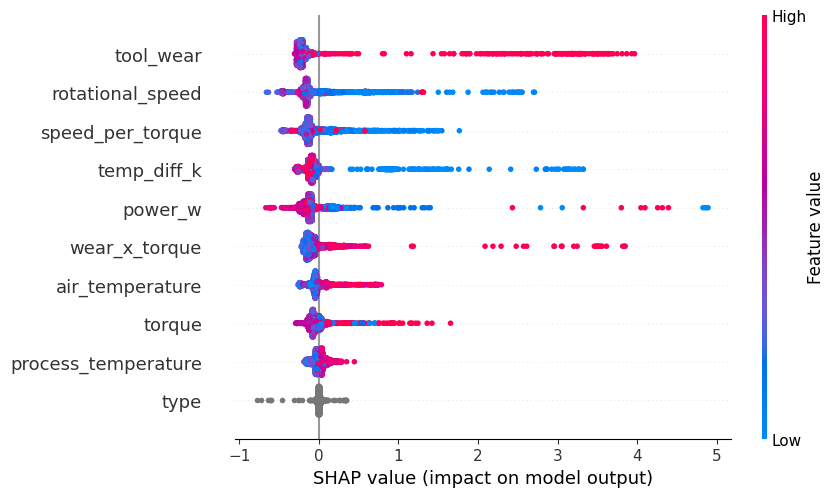

In [93]:
import shap

explainer = shap.TreeExplainer(lgb_best)
X_expl = X_test.sample(min(2000, len(X_test)), random_state=RANDOM_STATE)
sv = explainer(X_expl)
print('Форма SHAP:', sv.values.shape)

if sv.values.ndim == 3:
    values = sv.values[:, :, 1]
    base = sv.base_values[:, 1] if sv.base_values.ndim > 1 else sv.base_values
else:
    values = sv.values
    base = sv.base_values

sv_expl = shap.Explanation(
    values=values, base_values=base,
    data=X_expl.values,
    feature_names=X_expl.columns.tolist(),
)
shap.plots.beeswarm(sv_expl, max_display=15)

Топ-3 признака по SHAP: ['tool_wear', 'rotational_speed', 'speed_per_torque']


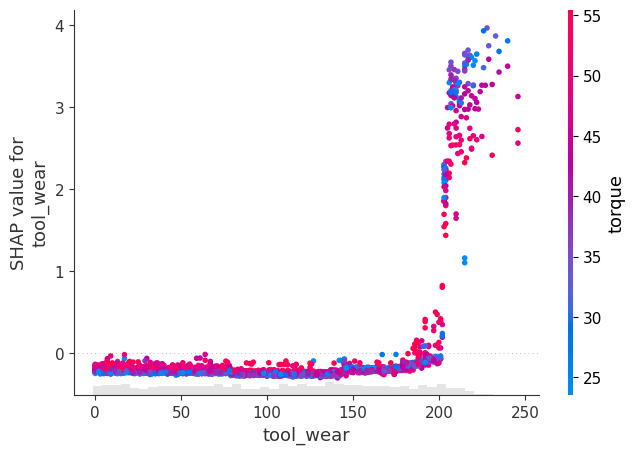

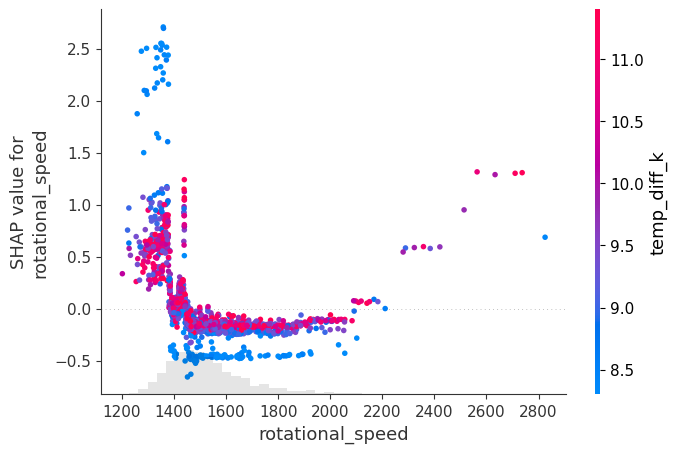

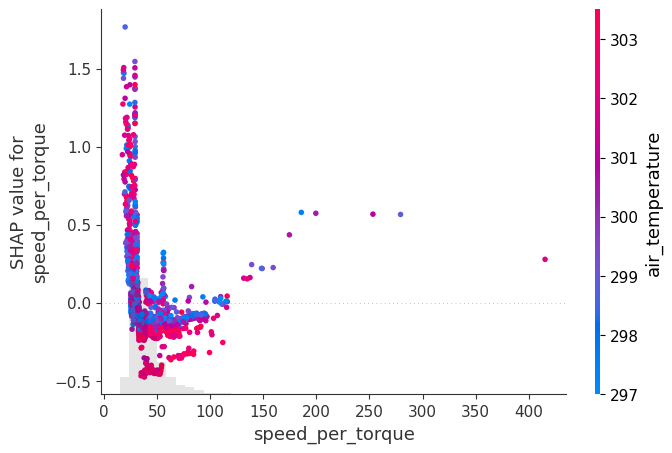

In [94]:
top_idx = np.argsort(-np.abs(sv_expl.values).mean(axis=0))[:3]
top_names = [X_expl.columns[i] for i in top_idx]
print('Топ-3 признака по SHAP:', top_names)
for i in top_idx:
    shap.plots.scatter(sv_expl[:, i], color=sv_expl)

TP — верное срабатывание 


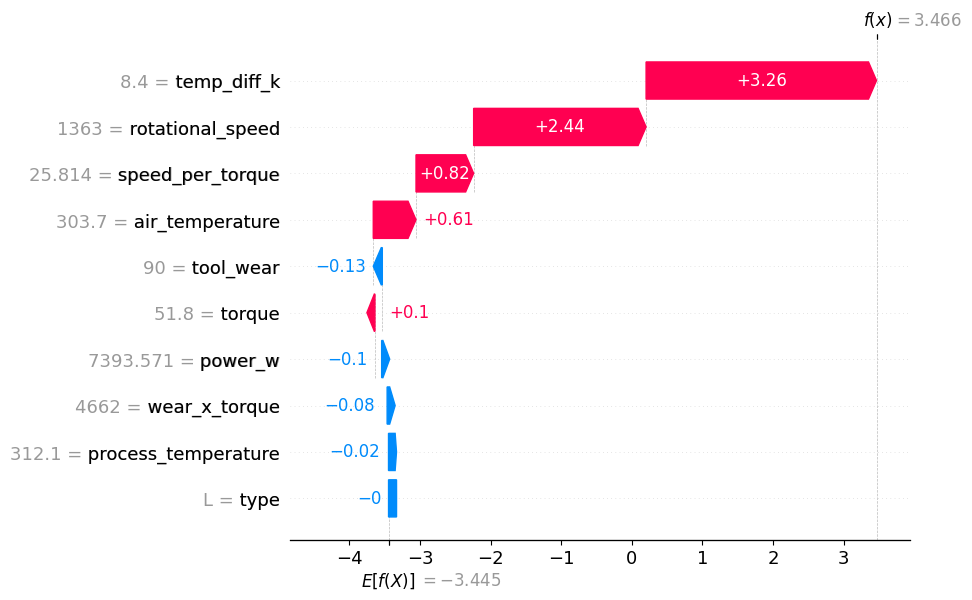

FP — ложная тревога 


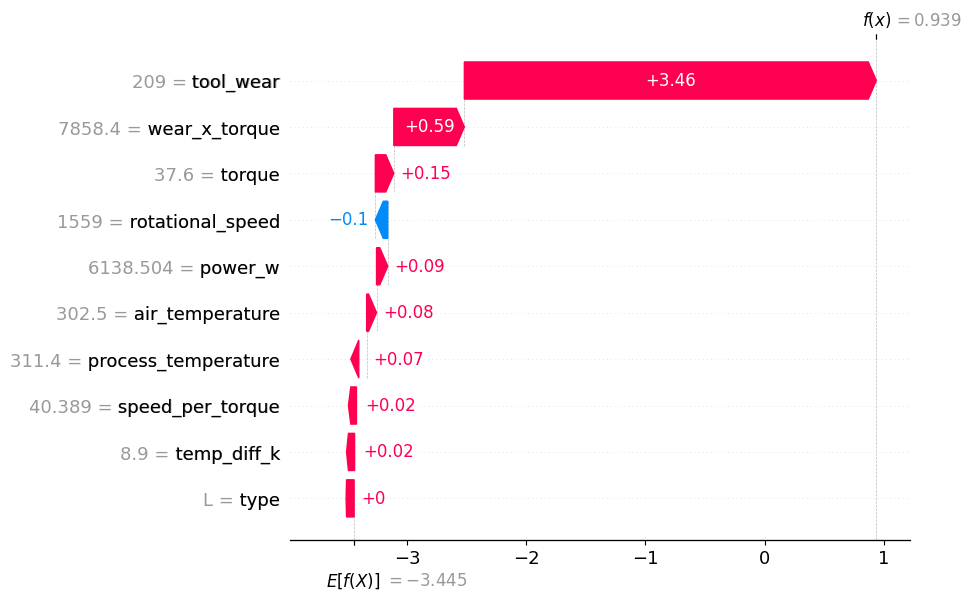

FN — пропуск 


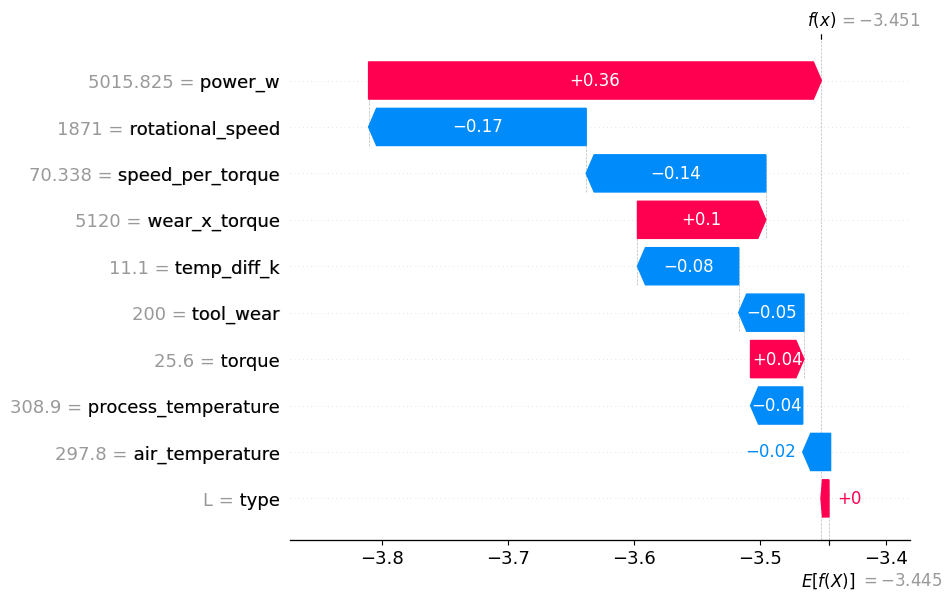

In [95]:
pred_test_bin = (proba_cal >= t_best).astype(int)
tp = np.where((pred_test_bin == 1) & (y_test.values == 1))[0]
fp = np.where((pred_test_bin == 1) & (y_test.values == 0))[0]
fn = np.where((pred_test_bin == 0) & (y_test.values == 1))[0]

sv_full = explainer(X_test, check_additivity=False)
if sv_full.values.ndim == 3:
    vals_full = sv_full.values[:, :, 1]
    base_full = (sv_full.base_values[:, 1]
                 if sv_full.base_values.ndim > 1 else sv_full.base_values)
else:
    vals_full = sv_full.values
    base_full = sv_full.base_values

sv_full_expl = shap.Explanation(
    values=vals_full, base_values=base_full,
    data=X_test.values,
    feature_names=X_test.columns.tolist(),
)

for label, idxs in [('TP — верное срабатывание', tp),
                    ('FP — ложная тревога',      fp),
                    ('FN — пропуск',             fn)]:
    if len(idxs):
        print(f'{label} ')
        shap.plots.waterfall(sv_full_expl[idxs[0]])

In [96]:
shap_imp = pd.Series(np.abs(sv_expl.values).mean(axis=0),
                     index=X_expl.columns)
gain_imp = pd.Series(lgb_best.booster_.feature_importance(importance_type='gain'),
                     index=X_train.columns)

comparison = pd.DataFrame({'SHAP': shap_imp, 'Gain': gain_imp})
comparison['SHAP_rank'] = comparison['SHAP'].rank(ascending=False).astype(int)
comparison['Gain_rank'] = comparison['Gain'].rank(ascending=False).astype(int)
print(comparison.sort_values('SHAP', ascending=False).round(4).to_string())

                       SHAP         Gain  SHAP_rank  Gain_rank
tool_wear            0.4161   71596.1686          1          4
rotational_speed     0.2612   77474.3207          2          3
speed_per_torque     0.2055   79425.1770          3          2
temp_diff_k          0.2019   28692.3936          4          7
power_w              0.1850  102504.4861          5          1
wear_x_torque        0.1623   34163.5170          6          5
air_temperature      0.0969   10387.8275          7          8
torque               0.0951   30098.0282          8          6
process_temperature  0.0595    5952.6499          9          9
type                 0.0174    2334.0341         10         10


### **Выводы по интерпретации модели (SHAP)**

1.  `tool_wear` (износ инструмента) — сильнейший признак. Чем выше износ, тем выше риск отказа. Это полностью согласуется с физикой: изношенный инструмент чаще ломается.
2.  `rotational_speed` (скорость вращения) — второй по важности. Высокая скорость увеличивает нагрузку и риск отказа.
3.  `speed_per_torque` — новый производный признак, который также оказался важен. Он улавливает дисбаланс между скоростью и моментом.
4.  `temp_diff_k` (разность температур) — четвёртый по важности. Перегрев (большая разность температур) ведёт к отказу.
5.  `power_w` (мощность) — пятый по важности. Высокая мощность — признак интенсивной работы и риска.

Сравнение с Gain:

Ранжирование по SHAP и Gain немного различается. Например, `power_w` имеет самый высокий Gain, но лишь пятый SHAP. Это связано с тем, что Gain измеряет, насколько часто признак использовался для разбиений, а SHAP — его фактический вклад в прогноз. Для интерпретации модели SHAP предпочтительнее.

Для заказчика:

Модель подтверждает, что главные факторы риска — это износ инструмента и интенсивный режим работы (высокая скорость, мощность). Это позволяет сформулировать рекомендации по обслуживанию.

## **Шаг 9. Сохранение модели**

Сохраняем полный Pipeline (признаки + калиброванная модель) и порог.

In [113]:
import joblib
from sklearn.preprocessing import FunctionTransformer


def _fe(X):
    """Один вызов: add_features + приведение type к category.

    Явно требуем DataFrame: FunctionTransformer(validate=False)
    пропускает numpy-массивы без проверки — это привело бы
    к неочевидной ошибке в add_features (обращение по имени столбца).
    """
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(X, columns=FEATURES)
    X = X.copy()
    X = add_features(X)
    X['type'] = X['type'].astype('category')
    return X


def make_full_pipeline(base_estimator):
    return Pipeline([
        ('fe', FunctionTransformer(_fe, validate=False)),
        ('model', base_estimator),
    ])


final_base = make_full_pipeline(lgb.LGBMClassifier(**best_params))
final_base.fit(df.loc[train_idx, FEATURES], y_train)

final_calibrated = CalibratedClassifierCV(final_base, method='sigmoid', cv=5)
final_calibrated.fit(df.loc[train_idx, FEATURES], y_train)

bundle = {
    'pipeline': final_calibrated,
    'threshold': float(t_best),
    'features_raw': FEATURES,
    'C_FN': C_FN, 'C_FP': C_FP,
    'positive_class': 'Machine failure',
    'notes': 'LightGBM final, CatBoost v2 as alternative in experiments.csv',
}
joblib.dump(bundle, 'model.joblib')

schema = {col: column_schema(df.loc[train_idx, col]) for col in FEATURES}
with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)
print('Модель и схема сохранены')

Модель и схема сохранены


In [114]:
def column_schema(s):
    if pd.api.types.is_numeric_dtype(s):
        return {'type': 'number',
                'min': float(s.min()), 'max': float(s.max())}
    return {'type': 'category',
            'values': sorted(s.dropna().astype(str).unique().tolist())}


schema = {col: column_schema(df.loc[train_idx, col]) for col in FEATURES}
with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

print(f'input_schema.json создан: {len(schema)} признаков')
first_key = list(schema)[0]
print(f'Пример: {first_key} → {schema[first_key]}')

input_schema.json создан: 6 признаков
Пример: type → {'type': 'category', 'values': ['H', 'L', 'M']}


In [115]:
from google.colab import files

print('Файлы в /content:')
!ls -la *.py *.joblib *.json *.csv 2>/dev/null
print()
for fname in ['features.py', 'model.joblib', 'input_schema.json', 'experiments.csv']:
    if os.path.exists(fname):
        files.download(fname)
        print('Скачан:', fname)
    else:
        print('НЕ найден:', fname)

Файлы в /content:
-rw-r--r-- 1 root root   19217 Sep 23 16:31 experiments.csv
-rw-r--r-- 1 root root    1709 Sep 23 14:41 features.py
-rw-r--r-- 1 root root     509 Sep 23 16:37 input_schema.json
-rw-r--r-- 1 root root 4453737 Sep 23 16:33 model.joblib



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Скачан: features.py


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Скачан: input_schema.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Скачан: experiments.csv


## **Выводы для заказчика**

1. **Риск отказа предсказуем.** Финальная модель LightGBM (порог 0.022)
   выявляет 95.6% отказов при точности 31.6%. Среди отобранных станков
   каждый третий действительно отказал бы.

2. **Сравнение бустингов на тестовой выборке:**

   | Модель | PR-AUC | ROC-AUC | CV↔Тест разрыв |
   |--------|--------|---------|----------------|
   | LogReg (baseline) | 0.451 | 0.941 | — |
   | CatBoost (Optuna v2) | 0.885 | 0.984 | 0.4 п.п. |
   | **LightGBM (Optuna)** | **0.910** | **0.986** | 1.4 п.п. |

   Оба бустинга **значимо превосходят** логистическую регрессию
   (95% ДИ разности PR-AUC не содержит 0). Разница между
   LightGBM и CatBoost — 2.5 п.п. — **в пределах статистической
   погрешности** (ДИ разности содержит 0). Для внедрения выбран
   LightGBM: он быстрее обучается и требует меньше памяти.

3. **Экономический эффект.** Оптимальный порог t=0.022 снижает
   суммарные потери с 13.60 млн ₽ (бездействие) до 2.01 млн ₽ —
   **экономия 11.59 млн ₽ (85.2%)**.

4. **Главные факторы риска** (SHAP):
   - **Износ инструмента (`tool_wear`)** — сильнейший предиктор.
   - **Скорость вращения (`rotational_speed`)**.
   - **Разность температур (`temp_diff_k`)** — перегрев.
   - **Мощность (`power_w`)** — подтверждает физическую гипотезу о перегрузке.

5. **Рекомендации по внедрению:**
   - Мониторинг в реальном времени с порогом P(failure) > 0.022.
   - Переобучение раз в квартал — оборудование изнашивается.
   - Контроль за появлением новых типов станков (вне L/M/H).

6. **Ограничения:**
   - Денежные оценки условны (C_FN = 200 000 ₽, C_FP = 10 000 ₽);
     уточнить по фактической отчётности.
   - Нет данных о вибрации, акустике, качестве сырья.
   - Модель обучена на исторических данных; предполагается
     стабильность условий эксплуатации.